# 05 - Gate-level leakage from the four transistor models (Part B, steps 4 and 5)

Self-contained notebook. Inputs: the 200 corners and the gate-level SPICE reference of notebook 04 (`data/corners.csv`, `data/gate_spice.csv`), the four saved transistor models of notebook 03 (`models/<case>.npz`), and ngspice with the model file (only for the oracle check in section 5).

For every gate, input pattern and corner of the SPICE reference:
1. the terminal voltages of every transistor are taken from the SPICE node voltages (supply, inputs, internal nodes, output), as the project text prescribes;
2. each transistor is sent to one of the four models (NMOS or PMOS, ON or OFF according to its gate voltage), together with its width, the corner's temperature, VDD and the process parameters of its type, and the model returns the four terminal currents;
3. the leakage of the gate is composed from these currents (section 2) and compared with the SPICE leakage.

Deliverables 6 (gate results table, 18 rows) and 7 (parity plot) are produced at the end.

## 1. Configuration, data and the saved models
`SavedModel` is the callable of notebook 03 (raw 12 columns in, currents `id, ig, is, ib` out; it canonicalises drain and source itself and swaps the currents back), copied here so that this notebook needs nothing else.

In [1]:
import json
import re
import shutil
import subprocess
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_FILE = ROOT / "Model Files-20261105" / "models" / "16nm_HP.pm"
BUILD_DIR, DATA_DIR, RESULT_DIR, MODEL_DIR = ROOT / "build", ROOT / "data", ROOT / "results", ROOT / "models"
LMIN = 16e-9
WMIN = LMIN
LDIFF = 2 * LMIN                      # AD = AS = W * LDIFF, as in the datasets and the gate netlists
PROC_PARAMS = ("vth0", "toxe", "ndep", "u0", "xj")
SPICE_OPTIONS = ".options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9"
NUMDGT = 15
N_WORKERS = 8
FEATS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj"]
KB_Q = 8.617333262e-5                 # k/q [V/K]
I0 = 1e-14                            # scale of the signed-log target used in notebook 03 [A]

XX = json.loads((DATA_DIR / "gate_sizing.json").read_text())["XX"]             # drive strength chosen in notebook 04
corners = pd.read_csv(DATA_DIR / "corners.csv")
gate_spice = pd.read_csv(DATA_DIR / "gate_spice.csv", dtype={"pattern": str})          # patterns like "00" must stay strings
print(corners.shape, gate_spice.shape)

(200, 13) (3600, 18)


In [2]:
# --- target transform and features exactly as in notebook 03 ---------------------------------------------------------
def vds_factor(vds, temp_c):
    vt = KB_Q * (np.asarray(temp_c) + 273.15)
    return np.clip(-np.expm1(-np.abs(vds) / vt), 1e-12, None)


def decode(y, vds, temp_c, vds_aware=True, i0=None):
    i0 = I0 if i0 is None else i0
    cur = i0 * np.sinh(np.asarray(y, dtype=float))
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] *= f
        cur[:, 2] *= f
    return cur


def make_features(d, device):
    sgn = 1.0 if device == "nmos" else -1.0
    vt = KB_Q * (d["temp"] + 273.15)
    vgs, vds, vbs, vgd = sgn * (d["vg"] - d["vs"]), sgn * (d["vd"] - d["vs"]), sgn * (d["vb"] - d["vs"]), sgn * (d["vg"] - d["vd"])
    X = d[FEATS].copy()
    X["inv_vt"] = 1.0 / vt
    X["vgs"], X["vds"], X["vbs"], X["vgd"] = vgs, vds, vbs, vgd
    X["vov_vt"] = (vgs - sgn * d["vth0"]) / vt
    X["vds_vt"] = vds / vt
    X["log_w"] = np.log(d["w"])
    return X


class SavedModel:
    """Callable model loaded from models/<case>.npz: raw 12 columns in, currents (id, ig, is, ib) out (numpy only)."""

    def __init__(self, path):
        z = np.load(path, allow_pickle=False)
        self.meta = json.loads(str(z["meta"]))
        self.x_mean, self.x_scale, self.y_mean, self.y_scale = z["x_mean"], z["x_scale"], z["y_mean"], z["y_scale"]
        self.w = {k[2:]: z[k] for k in z.files if k.startswith("w.")}

    @staticmethod
    def _silu(x):
        return x / (1.0 + np.exp(-x))

    def _forward(self, x):
        w, kind = self.w, self.meta["kind"]
        if kind == "mlp":
            n = len([k for k in w if k.endswith(".weight")])
            idx = sorted(int(k.split(".")[1]) for k in w if k.endswith(".weight"))
            for j, i in enumerate(idx):
                x = x @ w[f"net.{i}.weight"].T + w[f"net.{i}.bias"]
                if j < n - 1:
                    x = self._silu(x)
            return x
        h = self._silu(x @ w["inp.weight"].T + w["inp.bias"])
        for b in range(len([k for k in w if k.startswith("blocks.") and k.endswith(".0.weight")])):
            z = self._silu(h @ w[f"blocks.{b}.0.weight"].T + w[f"blocks.{b}.0.bias"]) @ w[f"blocks.{b}.2.weight"].T + w[f"blocks.{b}.2.bias"]
            h = self._silu(h + z)
        return h @ w["out.weight"].T + w["out.bias"]

    def __call__(self, raw):
        m, d = self.meta, pd.DataFrame(raw)[FEATS].astype(float).reset_index(drop=True)
        swap = (d["vd"] < d["vs"]) if m["device"] == "nmos" else (d["vd"] > d["vs"])
        d.loc[swap, ["vd", "vs"]] = d.loc[swap, ["vs", "vd"]].to_numpy()
        X = make_features(d, m["device"])[m["columns"]].to_numpy()
        y = self._forward((X - self.x_mean) / self.x_scale) * self.y_scale + self.y_mean
        vds = (d["vd"] - d["vs"]).abs().to_numpy()
        cur = decode(y, vds, d["temp"].to_numpy(), m["vds_aware"], m["i0"])
        cur[swap.to_numpy()] = cur[swap.to_numpy()][:, [2, 1, 0, 3]]            # id and is trade places back
        return cur


MODELS = {c: SavedModel(MODEL_DIR / f"{c}.npz") for c in ("nmos_on", "nmos_off", "pmos_on", "pmos_off")}
{c: m.meta["setting"] for c, m in MODELS.items()}

{'nmos_on': 'resnn, huber loss, 600 epochs (best epoch 538)',
 'nmos_off': 'resnn, mse loss, 600 epochs (best epoch 575)',
 'pmos_on': 'resnn, huber loss, 600 epochs (best epoch 598)',
 'pmos_off': 'resnn, mse loss, 600 epochs (best epoch 553)'}

## 2. The leakage of a gate
**SPICE reference.** The total leakage current of the gate, defined as in the instructor's inverter netlist: the power drawn from the supply and from the inputs held at VDD, divided by VDD (`leak_total` of notebook 04; an input at 0 V delivers no power). By Kirchhoff's laws it equals the current that flows from the VDD level to the 0 V level through the gate, and it is additive when gates drive each other.

**ML estimate: sum of the leakage components of every transistor.** The course material splits the leakage into three components, which map onto the four terminal currents of a transistor: **sub-threshold and GIDL** (the channel terminals, `id` and `is`), **gate** (`ig`) and **body / junction** (`ib`). For one transistor with the terminal voltages measured from its source terminal (the lower channel terminal for an NMOS, the higher one for a PMOS), the three terms are

`P_channel = (Vd - Vs)*Id + ...`, `P_gate = (Vg - Vs)*Ig`, `P_body = (Vb - Vs)*Ib`,

and the leakage of the gate is `(sum over all transistors of P_channel + P_gate + P_body) / VDD`. Because the four currents of a transistor sum to zero, the total power of a transistor equals this source-referenced sum, and (Tellegen's theorem) the transistor powers add up to the power delivered by the supply and the inputs: so with exact currents the sum reproduces the SPICE leakage exactly (checked in section 5 with real SPICE currents).

What this gives for the two states of a transistor:
* **OFF transistor:** all three terms are present. The channel term is the sub-threshold current weighted by the share of the supply voltage across the transistor (a stack of two OFF transistors shares the supply, so the stack current is counted once in total), the gate term is the gate tunnelling and the body term the junction current.
* **ON transistor:** its channel current is the leakage of the OFF transistor it is in series with, and it is weighted by its own small voltage `Vds` (micro- to millivolts), so it adds almost nothing; what remains is its gate and body leakage. The channel term is *kept* and not set to zero by hand, because an ON transistor can carry a real share of the supply (for example the upper NMOS of a NAND2 with inputs 10 has 0.25 V across it); section 5 shows that dropping the term gives errors of about 28 % there.

As a cross-check the notebook also composes the leakage by Kirchhoff's current law at the VDD-level nodes (the sum of the terminal currents of all transistor terminals tied to `vdd` or to an input held at VDD), which is equal to the SPICE leakage for exact currents.

## 3. Transistors of every gate and their terminal voltages
The topology is the one of notebook 04 (widths are multiples of `XX * Wmin`, with `XX` read from `data/gate_sizing.json`). For every SPICE operating point and every transistor of the gate, the table gets: drain, gate, source and bulk voltages from the recorded node voltages (`vdd`, `vss` = 0, inputs at 0 or VDD, `out`, `x`, `y`, `n`), the width, the temperature and VDD of the corner, and the five process parameters of its type from the corner (`n_*` for NMOS, `p_*` for PMOS). A transistor is **ON** if its gate voltage is above VDD/2 (NMOS) or below VDD/2 (PMOS), and then uses the `_on` model, otherwise the `_off` model. The gate voltage is the recorded one: for the transistors that are driven by an internal node (the INV in AND2 and OR2) it differs slightly from the rail, although the models were trained at exact rails.

In [3]:
# (name, type, drain, gate, source, bulk, width as a multiple of Wmin); same topology as notebook 04
GATES = {
    "inv": [("MP1", "pmos", "out", "a", "vdd", "vdd", 2 * XX), ("MN1", "nmos", "out", "a", "vss", "vss", 1 * XX)],
    "nand2": [("MP1", "pmos", "out", "a", "vdd", "vdd", 2 * XX), ("MP2", "pmos", "out", "b", "vdd", "vdd", 2 * XX),
              ("MN1", "nmos", "out", "a", "x", "vss", 2 * XX), ("MN2", "nmos", "x", "b", "vss", "vss", 2 * XX)],
    "nor2": [("MP1", "pmos", "y", "a", "vdd", "vdd", 4 * XX), ("MP2", "pmos", "out", "b", "y", "vdd", 4 * XX),
             ("MN1", "nmos", "out", "a", "vss", "vss", 1 * XX), ("MN2", "nmos", "out", "b", "vss", "vss", 1 * XX)],
    "and2": [("MP1", "pmos", "n", "a", "vdd", "vdd", 2 * XX), ("MP2", "pmos", "n", "b", "vdd", "vdd", 2 * XX),
             ("MN1", "nmos", "n", "a", "x", "vss", 2 * XX), ("MN2", "nmos", "x", "b", "vss", "vss", 2 * XX),
             ("MP3", "pmos", "out", "n", "vdd", "vdd", 2 * XX), ("MN3", "nmos", "out", "n", "vss", "vss", 1 * XX)],
    "or2": [("MP1", "pmos", "y", "a", "vdd", "vdd", 4 * XX), ("MP2", "pmos", "n", "b", "y", "vdd", 4 * XX),
            ("MN1", "nmos", "n", "a", "vss", "vss", 1 * XX), ("MN2", "nmos", "n", "b", "vss", "vss", 1 * XX),
            ("MP3", "pmos", "out", "n", "vdd", "vdd", 2 * XX), ("MN3", "nmos", "out", "n", "vss", "vss", 1 * XX)],
}
KEY = ["gate", "pattern", "corner"]
cn = corners.set_index("corner")


def device_table(points):
    """One row per (operating point, transistor) with its terminal voltages, geometry, corner and ON/OFF state."""
    parts = []
    for gate, devices in GATES.items():
        pts = points[points["gate"] == gate]
        nodes = {"vdd": pts["vdd"], "vss": pts["vdd"] * 0.0, "a": pts["a"] * pts["vdd"], "b": pts["b"].fillna(0) * pts["vdd"],
                 "out": pts["v_out"], "x": pts["v_x"], "y": pts["v_y"], "n": pts["v_n"]}
        for name, typ, d, g, s, b, w in devices:
            df = pd.DataFrame(dict(gate=gate, pattern=pts["pattern"].to_numpy(), corner=pts["corner"].to_numpy(), device=name, type=typ,
                                   vdd=pts["vdd"].to_numpy(), temp=pts["temp"].to_numpy(), w=w * WMIN,
                                   vd=nodes[d].to_numpy(), vg=nodes[g].to_numpy(), vs=nodes[s].to_numpy(), vb=nodes[b].to_numpy()))
            pre = "n" if typ == "nmos" else "p"
            for p in PROC_PARAMS:
                df[p] = cn.loc[df["corner"], f"{pre}_{p}"].to_numpy()
            df["on"] = (df["vg"] > df["vdd"] / 2) if typ == "nmos" else (df["vg"] < df["vdd"] / 2)
            df["case"] = typ + "_" + pd.Series(np.where(df["on"], "on", "off"))
            parts.append(df)
    return pd.concat(parts, ignore_index=True)


dev = device_table(gate_spice)
off_rail = np.where(dev["on"] == (dev["type"] == "nmos"), dev["vdd"], 0.0) - dev["vg"]
print(f"{len(dev)} transistor instances; per model: {dev['case'].value_counts().to_dict()}")
print(f"gate voltage minus the rail it should be at: median {np.abs(off_rail).median() * 1e3:.4f} mV, 99th percentile {np.abs(off_rail).quantile(0.99) * 1e3:.1f} mV, "
      f"largest {np.abs(off_rail).max() * 1e3:.1f} mV (only the INV inside AND2 / OR2 is not driven from a rail)")
dev.groupby(["gate", "device"], sort=False).agg(type=("type", "first"), W_nm=("w", lambda s: s.iloc[0] * 1e9), n=("w", "size"), on_share=("on", "mean"))

16800 transistor instances; per model: {'pmos_on': 4200, 'pmos_off': 4200, 'nmos_off': 4200, 'nmos_on': 4200}
gate voltage minus the rail it should be at: median 0.0000 mV, 99th percentile 10.0 mV, largest 29.2 mV (only the INV inside AND2 / OR2 is not driven from a rail)


type   W_nm    n  on_share
gate  device                            
inv   MP1     pmos   64.0  400      0.50
      MN1     nmos   32.0  400      0.50
nand2 MP1     pmos   64.0  800      0.50
      MP2     pmos   64.0  800      0.50
      MN1     nmos   64.0  800      0.50
      MN2     nmos   64.0  800      0.50
nor2  MP1     pmos  128.0  800      0.50
      MP2     pmos  128.0  800      0.50
      MN1     nmos   32.0  800      0.50
      MN2     nmos   32.0  800      0.50
and2  MP1     pmos   64.0  800      0.50
      MP2     pmos   64.0  800      0.50
      MN1     nmos   64.0  800      0.50
      MN2     nmos   64.0  800      0.50
      MP3     pmos   64.0  800      0.25
      MN3     nmos   32.0  800      0.75
or2   MP1     pmos  128.0  800      0.50
      MP2     pmos  128.0  800      0.50
      MN1     nmos   32.0  800      0.50
      MN2     nmos   32.0  800      0.50
      MP3     pmos   64.0  800      0.75
      MN3     nmos   32.0  800      0.25

## 4. Leakage from terminal currents
`components(dev, cur)` returns the channel, gate and body terms of every transistor and `gate_leakage` adds them up per operating point (power terms divided by VDD, in A). `kcl_leakage` is the cross-check by Kirchhoff's current law at the VDD-level nodes.

In [4]:
def components(dev, cur):
    """Channel, gate and body terms of every transistor in A (power terms / VDD), voltages referenced to the source terminal."""
    vd, vg, vs, vb = (dev[c].to_numpy() for c in ("vd", "vg", "vs", "vb"))
    ref = np.where((dev["type"] == "nmos").to_numpy(), np.minimum(vd, vs), np.maximum(vd, vs))      # the source terminal
    vdd = dev["vdd"].to_numpy()
    return pd.DataFrame(dict(channel=((vd - ref) * cur[:, 0] + (vs - ref) * cur[:, 2]) / vdd, gate=(vg - ref) * cur[:, 1] / vdd, body=(vb - ref) * cur[:, 3] / vdd))


def gate_leakage(dev, cur, drop_on_channel=False):
    """Per operating point: channel, gate, body and total leakage (A)."""
    c = components(dev, cur)
    if drop_on_channel:
        c.loc[dev["on"].to_numpy(), "channel"] = 0.0
    c["total"] = c.sum(axis=1)
    return c.groupby([dev["gate"].to_numpy(), dev["pattern"].to_numpy(), dev["corner"].to_numpy()]).sum().rename_axis(KEY)


# terminals of every transistor and the VDD-level nodes (the vdd net and inputs held at VDD)
TERMINAL_NODES = {(g, n): (d, gt, s, b) for g, devs in GATES.items() for n, t, d, gt, s, b, w in devs}


def kcl_leakage(dev, cur):
    pts = gate_spice.set_index(KEY)
    idx = pd.MultiIndex.from_arrays([dev["gate"], dev["pattern"], dev["corner"]])
    a, b = pts["a"].reindex(idx).to_numpy(), pts["b"].fillna(0).reindex(idx).to_numpy()
    nodes = np.array([TERMINAL_NODES[(g, n)] for g, n in zip(dev["gate"], dev["device"])])
    tot = np.zeros(len(dev))
    for k in range(4):
        at_vdd = (nodes[:, k] == "vdd") | ((nodes[:, k] == "a") & (a == 1)) | ((nodes[:, k] == "b") & (b == 1))
        tot += np.where(at_vdd, cur[:, k], 0.0)
    return pd.Series(tot).groupby([dev["gate"].to_numpy(), dev["pattern"].to_numpy(), dev["corner"].to_numpy()]).sum().rename_axis(KEY)


def ml_currents(dev):
    cur = np.zeros((len(dev), 4))
    for case, model in MODELS.items():
        sel = (dev["case"] == case).to_numpy()
        if sel.any():
            cur[sel] = model(dev.loc[sel, FEATS])
    return cur

## 5. Oracle check: the same composition with real SPICE currents
Before trusting any ML number, the pipeline of sections 3 and 4 is run with **single-transistor SPICE** in place of the models: every transistor instance of the table is simulated alone with the same four terminal voltages, temperature, width and process parameters, and its four currents go through the same composition. With exact currents the result must equal the SPICE leakage of the gate; any deviation would be a bug in the voltage mapping or in the composition, not an ML error. (It also shows what the leakage definition costs on its own.)

In [5]:
def to_wsl(path):
    p = Path(path).resolve()
    return "/mnt/" + p.drive.rstrip(":").lower() + "/" + "/".join(p.parts[1:])


def run_ngspice(cir_name, cwd):
    if shutil.which("ngspice"):
        r = subprocess.run(["ngspice", "-b", str(cir_name)], cwd=cwd, capture_output=True, text=True, errors="replace")
        return r.stdout.replace("\x00", "")
    r = subprocess.run(["wsl", "-e", "bash", "-c", f"cd '{to_wsl(cwd)}' && ngspice -b '{cir_name}' 2>/dev/null"], capture_output=True, text=True, errors="replace")
    return r.stdout.replace("\x00", "")


def fmt(x):
    return f"{float(x):.10g}"


def fet_netlist(device, df):
    r0 = df.iloc[0]
    lines = [f"* single-transistor batch ({device})", f".include {MODEL_FILE.name}", SPICE_OPTIONS,
             f"M1 d g s b {device} W={fmt(r0.w)} L={fmt(LMIN)} AD={fmt(r0.w * LDIFF)} AS={fmt(r0.w * LDIFF)}",
             f"Vd d 0 {fmt(r0.vd)}", f"Vg g 0 {fmt(r0.vg)}", f"Vs s 0 {fmt(r0.vs)}", f"Vb b 0 {fmt(r0.vb)}", ".control", f"set numdgt = {NUMDGT}"]
    for k, r in enumerate(df.itertuples(index=False)):
        lines.append(f"echo @@ {k}")
        lines += [f"altermod {device} {p}={fmt(getattr(r, p))}" for p in PROC_PARAMS]
        lines += [f"set temp = {fmt(r.temp)}", f"alter vd = {fmt(r.vd)}", f"alter vg = {fmt(r.vg)}", f"alter vs = {fmt(r.vs)}", f"alter vb = {fmt(r.vb)}",
                  f"alter @m1[w] = {fmt(r.w)}", f"alter @m1[ad] = {fmt(r.w * LDIFF)}", f"alter @m1[as] = {fmt(r.w * LDIFF)}", "op",
                  "print i(vd) i(vg) i(vs) i(vb) v(d) v(g) v(s) v(b)"]
    return "\n".join(lines + [".endc", ".end", ""])


_LINE = re.compile(r"^(@@) (\d+)$|^([iv])\((\w+)\) = (\S+)$")


def fet_chunk(device, df, tag):
    name = f"fet_{device}_{tag}.cir"
    (BUILD_DIR / name).write_text(fet_netlist(device, df), newline="\n")
    res, seen, k = np.full((len(df), 4), np.nan), {}, None
    for line in run_ngspice(name, BUILD_DIR).splitlines():
        m = _LINE.match(line.strip())
        if not m:
            continue
        if m.group(1):
            k = int(m.group(2)); seen[k] = {}
        elif k is not None:
            seen[k][f"{m.group(3)}({m.group(4)})"] = float(m.group(5))
    for k, d in seen.items():                         # accept a block only if the printed voltages are the ones that were set
        if k < len(df) and len(d) == 8 and all(abs(d[f"v({t})"] - df.iloc[k][v]) < 1e-9 for t, v in zip("dgsb", ("vd", "vg", "vs", "vb"))):
            res[k] = [-d[f"i(v{t})"] for t in "dgsb"]
    return res


def spice_currents(dev, chunk=250):
    BUILD_DIR.mkdir(exist_ok=True)
    shutil.copyfile(MODEL_FILE, BUILD_DIR / MODEL_FILE.name)
    cols = ["w", "vd", "vg", "vs", "vb", "temp", *PROC_PARAMS]
    jobs = [(typ, ix[s:s + chunk]) for typ in ("nmos", "pmos") for ix in [np.flatnonzero((dev["type"] == typ).to_numpy())] for s in range(0, len(ix), chunk)]
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        outs = list(ex.map(lambda j: fet_chunk(j[0], dev.iloc[j[1]][cols].reset_index(drop=True), f"{j[0]}_{j[1][0]}"), jobs))
    cur = np.full((len(dev), 4), np.nan)
    for (typ, ix), o in zip(jobs, outs):
        cur[ix] = o
    return cur


t0 = time.time()
cur_spice = spice_currents(dev)
print(f"{len(dev)} single-transistor simulations in {time.time() - t0:.0f} s; failed: {int(np.isnan(cur_spice).any(axis=1).sum())}")
ref = gate_spice.set_index(KEY)["leak_total"]
oracle = {name: (f(dev, cur_spice).reindex(ref.index) / ref - 1) for name, f in (
    ("component sum", lambda d, c: gate_leakage(d, c)["total"]),
    ("KCL at VDD", kcl_leakage),
    ("component sum without the channel term of ON transistors", lambda d, c: gate_leakage(d, c, drop_on_channel=True)["total"]))}
summ = pd.DataFrame({k: dict(median=v.abs().median(), p95=v.abs().quantile(0.95), largest=v.abs().max()) for k, v in oracle.items()}).T
summ.style.format("{:.2e}").set_caption("relative difference to the SPICE leakage with exact (SPICE) transistor currents")

16800 single-transistor simulations in 38 s; failed: 0


,median,p95,largest
component sum,1.08e-09,1.93e-07,9.26e-06
KCL at VDD,1.38e-08,1.81e-06,2.84e-04
component sum without the channel term of ON transistors,3.43e-03,2.78e-01,2.99e-01


In [6]:
assert oracle["component sum"].abs().max() < 1e-3 and oracle["KCL at VDD"].abs().max() < 1e-3, "composition does not reproduce the SPICE leakage"
by_case = pd.DataFrame({k: v.abs().groupby(level=["gate", "pattern"], sort=False).median() * 100 for k, v in oracle.items()})
by_case.columns = ["component sum", "KCL at VDD", "channel term of ON dropped"]
print("median |difference| to the SPICE leakage with exact currents, in % (cases where the third column is large are the ones where an ON transistor carries a share of the supply):")
by_case.round(4)

median |difference| to the SPICE leakage with exact currents, in % (cases where the third column is large are the ones where an ON transistor carries a share of the supply):


component sum  KCL at VDD  channel term of ON dropped
gate  pattern                                                       
inv   0                  0.0      0.0000                      0.0650
      1                  0.0      0.0000                      0.2332
nand2 00                 0.0      0.0006                      0.0003
      01                 0.0      0.0000                      0.2211
      10                 0.0      0.0000                     27.4403
      11                 0.0      0.0000                      0.4310
nor2  00                 0.0      0.0000                      0.1211
      01                 0.0      0.0000                      0.6891
      10                 0.0      0.0000                     27.8441
      11                 0.0      0.0000                      0.0003
and2  00                 0.0      0.0000                      0.2323
      01                 0.0      0.0000                      0.2951
      10                 0.0      0.0000                      2.3330
      11                 0.0      0.0000                      0.3937
or2   00                 0.0      0.0000                      0.2493
      01                 0.0      0.0000                      0.6095
      10                 0.0      0.0000                     12.7645
      11                 0.0      0.0000                      0.0623

## 6. Gate leakage from the ML models
All 16,800 transistor instances go through the saved models (a fraction of a second); the composition is the same as in section 5.

In [7]:
t0 = time.time()
cur_ml = ml_currents(dev)
comp_ml = gate_leakage(dev, cur_ml)
kcl_ml = kcl_leakage(dev, cur_ml)
comp_sp = gate_leakage(dev, cur_spice)
print(f"{len(dev)} transistor predictions in {time.time() - t0:.1f} s")

res = gate_spice.set_index(KEY).copy()
res["ml_leak"] = comp_ml["total"].reindex(res.index)
res["ml_channel"], res["ml_gate"], res["ml_body"] = (comp_ml[c].reindex(res.index) for c in ("channel", "gate", "body"))
res["ml_leak_kcl"] = kcl_ml.reindex(res.index)
res["spice_channel"], res["spice_gate"], res["spice_body"] = (comp_sp[c].reindex(res.index) for c in ("channel", "gate", "body"))
res["err"] = res["ml_leak"] / res["leak_total"] - 1                       # signed relative error (ML - SPICE) / SPICE
res["err_kcl"] = res["ml_leak_kcl"] / res["leak_total"] - 1
res = res.reset_index()
res.to_csv(DATA_DIR / "gate_ml.csv", index=False, float_format="%.12g")
print("saved data/gate_ml.csv:", res.shape)
# per-transistor terms (ML and SPICE currents through the same composition) for the error analysis of notebook 07
cm, cs = components(dev, cur_ml), components(dev, cur_spice)
dev_out = dev[["gate", "pattern", "corner", "device", "type", "case", "on", "w"]].copy()
for c in ("channel", "gate", "body"):
    dev_out[f"ml_{c}"], dev_out[f"spice_{c}"] = cm[c].to_numpy(), cs[c].to_numpy()
dev_out.to_csv(DATA_DIR / "gate_devices.csv", index=False, float_format="%.10g")
print("saved data/gate_devices.csv:", dev_out.shape)
res[["gate", "pattern", "corner", "temp", "vdd", "leak_total", "ml_leak", "err", "ml_leak_kcl", "err_kcl"]].head()

16800 transistor predictions in 1.2 s


saved data/gate_ml.csv: (3600, 28)


saved data/gate_devices.csv: (16800, 14)


,gate,pattern,corner,temp,vdd,leak_total,ml_leak,err,ml_leak_kcl,err_kcl
0,inv,0,0,29.991131,0.867503,1.875168e-08,1.892527e-08,0.009257,1.918075e-08,0.022881
1,inv,1,0,29.991131,0.867503,3.200908e-07,3.238628e-07,0.011784,3.264128e-07,0.019751
2,inv,0,1,56.352005,0.881495,7.200452e-08,7.206300e-08,0.000812,7.259608e-08,0.008216
3,inv,1,1,56.352005,0.881495,2.004216e-07,1.914338e-07,-0.044845,2.006437e-07,0.001108
4,inv,0,2,71.587137,0.890086,3.622971e-08,3.602853e-08,-0.005553,3.638459e-08,0.004275


## 7. Gate results table (deliverable 6)
For each of the 18 gate and input cases (200 corners each): the median SPICE leakage, the median ML leakage, the **bias** (mean of the signed relative error `(ML - SPICE) / SPICE`), the **median** and the **95th percentile** of the absolute relative error, and, as the spec speaks of "mean accuracy", the **mean** absolute relative error. Leakage in A, errors in %.

In [8]:
def table(res, err="err", leak="ml_leak"):
    g = res.groupby(["gate", "pattern"], sort=False)
    out = pd.DataFrame({"SPICE median [A]": g["leak_total"].median(), "ML median [A]": g[leak].median(),
                        "bias [%]": g[err].mean() * 100, "median error [%]": g[err].apply(lambda s: s.abs().median()) * 100,
                        "95th pct error [%]": g[err].apply(lambda s: s.abs().quantile(0.95)) * 100, "mean error [%]": g[err].apply(lambda s: s.abs().mean()) * 100})
    return out


gate_table = table(res)
gate_table.to_csv(RESULT_DIR / "gate_results.csv")
overall = pd.Series({"median error [%]": res["err"].abs().median() * 100, "95th pct error [%]": res["err"].abs().quantile(0.95) * 100,
                     "mean error [%]": res["err"].abs().mean() * 100, "bias [%]": res["err"].mean() * 100})
print("all 3,600 operating points:", overall.round(2).to_dict())
gate_table.style.format({"SPICE median [A]": "{:.3e}", "ML median [A]": "{:.3e}", "bias [%]": "{:+.2f}", "median error [%]": "{:.2f}", "95th pct error [%]": "{:.2f}", "mean error [%]": "{:.2f}"})

all 3,600 operating points: {'median error [%]': 1.49, '95th pct error [%]': 7.36, 'mean error [%]': 2.34, 'bias [%]': -0.75}


Cross-check with the other composition (Kirchhoff's current law at the VDD-level nodes), same models, same node voltages, per gate type:

In [9]:
alt = pd.DataFrame({"component sum": res.groupby("gate", sort=False)["err"].apply(lambda s: s.abs().median()) * 100,
                    "KCL at VDD": res.groupby("gate", sort=False)["err_kcl"].apply(lambda s: s.abs().median()) * 100})
alt.loc["all"] = [res["err"].abs().median() * 100, res["err_kcl"].abs().median() * 100]
print("median absolute error [%] by gate type:")
alt.round(2)

median absolute error [%] by gate type:


,component sum,KCL at VDD
gate,,
inv,2.05,1.52
nand2,0.85,1.21
nor2,1.20,1.29
and2,2.66,2.11
or2,1.70,1.27
all,1.49,1.39


## 8. Parity plot (deliverable 7)
ML leakage against SPICE leakage for all 3,600 gate simulations, on log axes; the dashed line is the identity and the dotted lines are +/- 10 %.

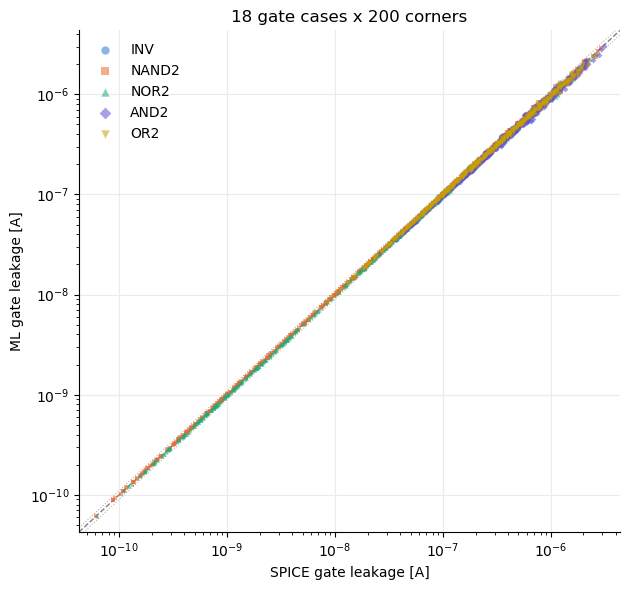

In [10]:
COL = {"inv": "#2a78d6", "nand2": "#eb6834", "nor2": "#1baf7a", "and2": "#6250d6", "or2": "#c8a000"}
MARK = {"inv": "o", "nand2": "s", "nor2": "^", "and2": "D", "or2": "v"}
fig, ax = plt.subplots(figsize=(6.4, 6))
lo, hi = res["leak_total"].min() * 0.7, res["leak_total"].max() * 1.4
ax.plot([lo, hi], [lo, hi], "--", color="0.5", lw=1, zorder=1)
for f in (0.9, 1.1):
    ax.plot([lo, hi], [lo * f, hi * f], ":", color="0.7", lw=0.8, zorder=1)
for g, d in res.groupby("gate", sort=False):
    ax.scatter(d["leak_total"], d["ml_leak"], s=9, marker=MARK[g], color=COL[g], alpha=0.55, linewidths=0, label=g.upper(), zorder=2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("SPICE gate leakage [A]"); ax.set_ylabel("ML gate leakage [A]")
ax.set_title("18 gate cases x 200 corners")
ax.legend(frameon=False, markerscale=2, loc="upper left")
ax.grid(color="0.92", lw=0.8); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULT_DIR / "gate_parity.png", dpi=120)
plt.show()